<a href="https://colab.research.google.com/github/homiecal/dap-playground/blob/master/multiple-disease-impact-on-interpretability-VLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Multiple disease impact on interpretability VLM**


In [2]:
import torch
print(torch.cuda.is_available())


True


In [3]:
!git clone https://github.com/hila-chefer/Transformer-MM-Explainability

# import os
# os.chdir(f'./Transformer-MM-Explainability')

!pip install -q einops ftfy captum

fatal: destination path 'Transformer-MM-Explainability' already exists and is not an empty directory.


# **CLIP** (CheXzero)

Load the CLIP architecture from Chefer [8] library (Transformer-MM-Explainability), then load the ChexZero model weights.

The ChexZero model checkpoint weights can be downloaded from [here](https://drive.google.com/drive/folders/1makFLiEMbSleYltaRxw81aBhEDMpVwno?usp=sharing) otherwise revisit the [README.md](https://github.com/rajpurkarlab/CheXzero/tree/main) from the repository.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
!git clone https://github.com/rajpurkarlab/CheXzero.git

fatal: destination path 'CheXzero' already exists and is not an empty directory.


In [6]:
%%capture
import warnings
warnings.filterwarnings("ignore")

# Ignore non-issue warnings with builds for CheXzero
!pip install -q -r CheXzero/requirements.txt

In [7]:
%%capture
!pip -q install h5py torchio clip

In [8]:
import os
os.getcwd()

'/content'

In [9]:
# Import Chefer CLIP function to ensure underlying CLIP structure captures the forward pass attention, and backward pass gradients
import sys

sys.path.insert(0, "/content/Transformer-MM-Explainability")

import CLIP.clip as clip
from CLIP.clip.model import CLIP

print(clip.__file__)

/content/Transformer-MM-Explainability/CLIP/clip/__init__.py


In [10]:
import torch
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
from captum.attr import visualization

if not hasattr(Image, "ANTIALIAS"):
    Image.ANTIALIAS = Image.Resampling.LANCZOS

In [11]:
sys.path.insert(0, "/content/CheXzero")

from CheXzero.data_process import preprocess, img_to_hdf5
from CheXzero.zero_shot import CXRTestDataset

### Load ChezXero weights into CLIP

In [12]:
MODEL_CHECKPOINT = "/content/drive/MyDrive/Research/model-weights/chexzero/best_64_0.0001_original_35000_0.864.pt"

In [13]:
import sys
def load_clip(model_path, pretrained=False, context_length=77):
    """
    FUNCTION: load_clip
    ---------------------------------
    """
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if pretrained is False:
        # use new model params
        params = {
            'embed_dim':512,
            'image_resolution': 224,
            'vision_layers': 12,
            'vision_width': 768,
            'vision_patch_size': 32,
            'context_length': context_length,
            'vocab_size': 49408,
            'transformer_width': 512,
            'transformer_heads': 8,
            'transformer_layers': 12
        }

        model = CLIP(**params)
    else:
        model, preprocess = clip.load("ViT-B/32", device=device, jit=False)
    try:
        model.load_state_dict(torch.load(model_path, map_location=device))
    except:
        print("Argument error. Set pretrained = True.", sys.exc_info()[0])
        raise
    return model


In [14]:
model = load_clip(MODEL_CHECKPOINT, False)

## Intepretability Chefer et. al and Visualisation functions

Copied and adapted from [CLIP-explainability.ipynb](https://github.com/hila-chefer/Transformer-MM-Explainability/blob/main/CLIP_explainability.ipynb).

In [15]:
#@title Control context expansion (number of attention layers to consider)
#@title Number of layers for image Transformer
start_layer =  -1#@param {type:"number"}

#@title Number of layers for text Transformer
start_layer_text =  -1#@param {type:"number"}

In [16]:
def interpret(image, texts, model, device, start_layer=start_layer, start_layer_text=start_layer_text):
    batch_size = texts.shape[0]
    images = image.repeat(batch_size, 1, 1, 1)
    logits_per_image, logits_per_text = model(images, texts)
    probs = logits_per_image.softmax(dim=-1).detach().cpu().numpy()
    index = [i for i in range(batch_size)]
    one_hot = np.zeros((logits_per_image.shape[0], logits_per_image.shape[1]), dtype=np.float32)
    one_hot[torch.arange(logits_per_image.shape[0]), index] = 1
    one_hot = torch.from_numpy(one_hot).requires_grad_(True)
    one_hot = torch.sum(one_hot.cuda() * logits_per_image)
    model.zero_grad()

    image_attn_blocks = list(dict(model.visual.transformer.resblocks.named_children()).values())

    if start_layer == -1:
      # calculate index of last layer
      start_layer = len(image_attn_blocks) - 1

    num_tokens = image_attn_blocks[0].attn_probs.shape[-1]
    R = torch.eye(num_tokens, num_tokens, dtype=image_attn_blocks[0].attn_probs.dtype).to(device)
    R = R.unsqueeze(0).expand(batch_size, num_tokens, num_tokens)
    for i, blk in enumerate(image_attn_blocks):
        if i < start_layer:
          continue
        grad = torch.autograd.grad(one_hot, [blk.attn_probs], retain_graph=True)[0].detach()
        cam = blk.attn_probs.detach()
        cam = cam.reshape(-1, cam.shape[-1], cam.shape[-1])
        grad = grad.reshape(-1, grad.shape[-1], grad.shape[-1])
        cam = grad * cam
        cam = cam.reshape(batch_size, -1, cam.shape[-1], cam.shape[-1])
        cam = cam.clamp(min=0).mean(dim=1)
        R = R + torch.bmm(cam, R)
    image_relevance = R[:, 0, 1:]


    text_attn_blocks = list(dict(model.transformer.resblocks.named_children()).values())

    if start_layer_text == -1:
      # calculate index of last layer
      start_layer_text = len(text_attn_blocks) - 1

    num_tokens = text_attn_blocks[0].attn_probs.shape[-1]
    R_text = torch.eye(num_tokens, num_tokens, dtype=text_attn_blocks[0].attn_probs.dtype).to(device)
    R_text = R_text.unsqueeze(0).expand(batch_size, num_tokens, num_tokens)
    for i, blk in enumerate(text_attn_blocks):
        if i < start_layer_text:
          continue
        grad = torch.autograd.grad(one_hot, [blk.attn_probs], retain_graph=True)[0].detach()
        cam = blk.attn_probs.detach()
        cam = cam.reshape(-1, cam.shape[-1], cam.shape[-1])
        grad = grad.reshape(-1, grad.shape[-1], grad.shape[-1])
        cam = grad * cam
        cam = cam.reshape(batch_size, -1, cam.shape[-1], cam.shape[-1])
        cam = cam.clamp(min=0).mean(dim=1)
        R_text = R_text + torch.bmm(cam, R_text)
    text_relevance = R_text

    return text_relevance, image_relevance

In [17]:
def show_image_relevance(image_relevance, image, orig_image, bboxes=None):
    # create heatmap from mask on image
    def show_cam_on_image(img, mask):
        heatmap = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
        heatmap = np.float32(heatmap) / 255
        cam = heatmap + np.float32(img)
        cam = cam / np.max(cam)
        return cam

    num_subplots = 2 if bboxes is None else 3
    fig, axs = plt.subplots(1, num_subplots)
    axs[0].imshow(orig_image);
    axs[0].axis('off');
    axs[1].set_title("Original Image")


    dim = int(image_relevance.numel() ** 0.5)
    image_relevance = image_relevance.reshape(1, 1, dim, dim)
    image_relevance = torch.nn.functional.interpolate(image_relevance, size=(image.shape[-2], image.shape[-1]), mode='bilinear')
    image_relevance = image_relevance.reshape(image.shape[-2], image.shape[-1]).cuda().data.cpu().numpy()
    image_relevance = (image_relevance - image_relevance.min()) / (image_relevance.max() - image_relevance.min())

    # image_relevance = torch.nn.functional.interpolate(orig_image, size=224, mode='bilinear')
    image = image[0].permute(1, 2, 0).data.cpu().numpy()
    image = (image - image.min()) / (image.max() - image.min())
    vis = show_cam_on_image(image, image_relevance)
    vis = np.uint8(255 * vis)
    vis = cv2.cvtColor(np.array(vis), cv2.COLOR_RGB2BGR)
    axs[1].imshow(vis);
    axs[1].axis('off');
    axs[1].set_title("Interpretability Map")

      # Draw GT boxes on original image
    if bboxes is not None:
        axs[2].imshow(orig_image)
        axs[2].axis('off')
        axs[2].set_title("Ground Truth")
        orig_w, orig_h = orig_image.size

        for bbox in bboxes:
            x1, y1, x2, y2 = bbox

            # Normalised coordinates -> original image pixels
            x1 *= orig_w
            x2 *= orig_w
            y1 *= orig_h
            y2 *= orig_h

            rect = plt.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                linewidth=2
            )
            axs[2].imshow(orig_image);
            axs[2].add_patch(rect)

In [18]:
from CLIP.clip.simple_tokenizer import SimpleTokenizer as _Tokenizer
_tokenizer = _Tokenizer()

def show_heatmap_on_text(text, text_encoding, R_text):
  CLS_idx = text_encoding.argmax(dim=-1)
  R_text = R_text[CLS_idx, 1:CLS_idx]
  text_scores = R_text / R_text.sum()
  text_scores = text_scores.flatten()
  print(text_scores)
  text_tokens=_tokenizer.encode(text)
  text_tokens_decoded=[_tokenizer.decode([a]) for a in text_tokens]
  vis_data_records = [visualization.VisualizationDataRecord(text_scores,0,0,0,0,0,text_tokens_decoded,1)]
  visualization.visualize_text(vis_data_records)

## Transform and Visualisation functions


In [32]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

In [20]:

class color:
   PURPLE = '\033[95m'
   CYAN = '\033[96m'
   DARKCYAN = '\033[36m'
   BLUE = '\033[94m'
   GREEN = '\033[92m'
   YELLOW = '\033[93m'
   RED = '\033[91m'
   BOLD = '\033[1m'
   UNDERLINE = '\033[4m'
   END = '\033[0m'

In [21]:
def get_texts_and_bboxes(image_id, gt_by_image):
  gt_report = gt_by_image[image_id]

  texts = []
  bboxes = []
  for i in gt_report["findings"]:
    texts.append(i['sentence_en'])

    if 'boxes' in i.keys():
      bboxes.append(tuple(box for box in i['boxes']))
    else:
      bboxes.append([])
  return texts, bboxes

In [22]:
def get_texts_and_bboxes_abnormal(image_id, gt_by_image):
  gt_report = gt_by_image[image_id]

  texts = []
  bboxes = []
  for i in gt_report["findings"]:
    if not i['abnormal'] or ('boxes' not in i.keys() or len(i['boxes']) == 0):
      continue
    texts.append(i['sentence_en'])
    bboxes.append(tuple(box for box in i['boxes']))

    # if 'boxes' in i.keys():
    #   bboxes.append(tuple(box for box in i['boxes']))
    # else:
    #   bboxes.append([])
  return texts, bboxes

In [23]:
def get_interpret(image_relevance):
    dim = int(image_relevance.numel() ** 0.5)
    image_relevance = image_relevance.reshape(1, 1, dim, dim)
    image_relevance = torch.nn.functional.interpolate(image_relevance, size=224, mode='bilinear')
    image_relevance = image_relevance.reshape(224, 224).cuda().data.cpu()
    image_relevance = (image_relevance - image_relevance.min()) / (image_relevance.max() - image_relevance.min())
    return image_relevance

In [24]:
def dice_score(image_relevance, bboxes, thresholds):

  image_relevance = get_interpret(image_relevance)
  scores = {}
  for i in thresholds:
    pred = image_relevance > i

    gt_mask = torch.zeros((224, 224), dtype=torch.bool)
    for bbox in bboxes:
      x1, y1, x2, y2 = bbox
      resize_h, resize_w = image_relevance.shape[-2:]
      x1 = round(x1 * resize_w)
      x2 = round(x2 * resize_w)
      y1 = round(y1 * resize_h)
      y2 = round(y2 * resize_h)
      gt_mask[y1:y2, x1:x2] = True

    intersection = (gt_mask & pred).sum()
    dice = (2*intersection / (gt_mask.sum() + pred.sum())).item()
    scores[f"dice_at_{i}"] = dice
  return scores

In [35]:
def bbox_percent(bbox):
  x1, y1, x2, y2 = bbox
  width, length = x2 - x1, y2 - y1
  bboxes_percent_img = length * width
  return bboxes_percent_img

# TODO


## PadChest-GR Interpretability Visualisation Example

You can download PadChest-GR dataset from https://bimcv.cipf.es/bimcv-projects/padchest/


In [25]:
import json
import glob
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import Compose, Normalize

GROUNDED_REPORTS = "/content/drive/MyDrive/Research/data/padchest-gr/grounded_reports_20240819.json"
with open(
   GROUNDED_REPORTS,
    encoding="utf-8",
) as f:
    gt_by_image = {record["ImageID"]: record for record in json.load(f)}
IMAGE_FOLDER = "/content/drive/MyDrive/Research/data/padchest-gr/PadChest_GR/"
image_paths = glob.glob(f"{IMAGE_FOLDER}/*.png")


In [26]:

# Read image
def read_image(img_path) -> Image.Image:
    img = cv2.imread(str(img_path))
    # convert to PIL Image object
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_pil = Image.fromarray(img)
    return img_pil

# Resize and pad
def preprocess(img, desired_size=320):
    old_size = img.size

    # Here we calculate the ratio between the largest side to the desired size, if the original image
    # is larger than the desired size this number will be between 0 and 1, we then scale the original
    # image down using this ratio, the new_size for the largest side should equal the desired size exactly,
    # with the smaller side being less than the desired size
    ratio = float(desired_size)/max(old_size)
    new_size = tuple([int(x*ratio) for x in old_size])

    # The image is now resized to the new size (maintaing its aspect ratio)
    img = img.resize(new_size, Image.ANTIALIAS)

    # A blank image is created with the desired size, then the resize image is pasted on it, centered, determined by the offset
    # calculated, there will only be 1 offset for either width or height.
    width_offset = (desired_size-new_size[0])//2
    height_offset = (desired_size-new_size[1])//2
    new_img = Image.new('RGB', (desired_size, desired_size))
    new_img.paste(img, (width_offset, height_offset))

    # Return offsets as a percentage, because bounding boxes are given as a ratio of image
    return new_img, (width_offset/desired_size, height_offset/desired_size)

# Transforms 
def to_torch(img_pil: Image.Image) -> torch.Tensor:
    img_arr = np.asarray(img_pil)  # H, W, C
    return torch.from_numpy(img_arr).float().permute(2,0,1) # -> C, H, W


transforms = Compose([
    to_torch,
    Normalize(
        (101.48761,) * 3,
        (83.43944,) * 3
    ),
])


In [27]:
class PadChestDataset(Dataset):
    def __init__(self, image_paths, gt_by_image, transform, abnormal_labels_only = True):

        self.gt_by_image = gt_by_image
        self.transform = transform

        self.abnormal_labels_only = abnormal_labels_only 

        if abnormal_labels_only:
            # Images with abnormal findings and bounding boxes 
            self.samples = [(Path(path), Path(path).name) for path in image_paths if self.image_contains_abnormal_w_labels(self.gt_by_image[Path(path).name])]
        else:
            self.samples = [(Path(path), Path(path).name) for path in image_paths]

        missing = [
            image_id
            for _, image_id in self.samples
            if image_id not in gt_by_image
        ]
        if missing:
            raise ValueError(
                f"Missing annotations for {len(missing)} image(s), "
                f"for example: {missing[:5]}"
            )

    @staticmethod
    def image_contains_abnormal_w_labels(image_findings_id: dict) -> bool:
        for finding in image_findings_id["findings"]:
            if finding["abnormal"] and "boxes" in finding.keys() and finding["boxes"]:
                return True
        return False

    def get_item_by_id(self, image_id):
        for index, (_, id) in enumerate(self.samples):
            if id == image_id:
                return self.__getitem__(index)
        raise ValueError(f"Image ID {image_id} not found in dataset.")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, image_id = self.samples[index]

        # Apply the same preprocessing used for your single-image inference.
        # read image using cv2
        img_pil = read_image(str(path))

        # Applly padchest pre processing
        img, (width_offset, height_offset) = preprocess(img_pil, desired_size=224)   

        # Normalise and convert to tensor
        img = transforms(img)

        # Get bboxes and texts for the image
        texts, bboxes = get_texts_and_bboxes_abnormal(
            image_id, self.gt_by_image
        )

        # Adjust bboxes percentages by their offset percentages
        bboxes = [[(x1 + width_offset, y1 + height_offset, x2 + width_offset, y2 + height_offset) for x1, y1, x2, y2 in i] for i in bboxes]

        return image_id, img, texts, bboxes, (width_offset, height_offset)

In [28]:
padchest_abnormal_dataset = PadChestDataset(image_paths, gt_by_image, transforms, True)
padchest_dataset = PadChestDataset(image_paths, gt_by_image, transforms, False)

In [29]:
# Custom collate fn to keep only 1 sample per batch - Chefer interpret template function setup for 1 image so keep it 
# simple given the sample from PadChest-GR is small
def collate_fn_return_one(batch):
    return batch[0]

padchest_abnormal_loader = DataLoader(padchest_abnormal_dataset, batch_size=1, shuffle=False, collate_fn=collate_fn_return_one)

In [30]:
def show_for_one_image(image_id, model, thresholds = [0.3,0.4,0.5], custom_texts=None):

    image_id, image, texts, bboxes, offsets = padchest_abnormal_dataset.get_item_by_id(image_id)

    image = image.unsqueeze(0).to(device)

    if custom_texts:
       texts = custom_texts

    if texts:
      text = clip.tokenize(texts).to(device)

      R_text, R_image = interpret(model=model, image=image, texts=text, device=device)
      batch_size = text.shape[0]
      dice_results = []
      for i in range(batch_size):
        show_heatmap_on_text(texts[i], text[i], R_text[i])
        show_image_relevance(R_image[i], image, orig_image=Image.open(f"{IMAGE_FOLDER}/{image_id}"), bboxes=bboxes[i])
        plt.show()
        results = dice_score(R_image[i], bboxes[i], thresholds)
        dice_results.append(results)

      print(dice_results)
      print(image_id)

    return dice_results

tensor([2.7982e-02, 4.2612e-03, 1.8029e-02, 4.9655e-03, 1.2658e-03, 8.7036e-03,
        1.9967e-04, 1.3712e-02, 2.1284e-03, 3.5240e-02, 1.4101e-02, 1.0097e-02,
        4.6871e-03, 2.5943e-05, 8.8091e-04, 1.5912e-02, 1.9372e-01, 3.7638e-01,
        2.5007e-02, 1.3324e-02, 3.2998e-03, 9.9017e-02, 2.8693e-02, 3.4692e-02,
        6.3678e-02], device='cuda:0')


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
0,0 (0.00),0,0.00,"dex tro conve x or le vo conve x spinal cur v ature with associated verte bral rotation , consistent with sco li osis ."


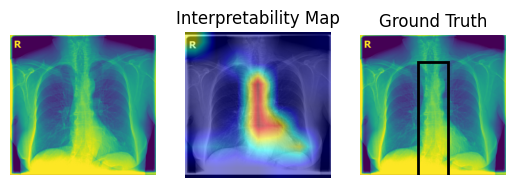

[{'dice_at_0.3': 0.632245659828186, 'dice_at_0.4': 0.5987969636917114, 'dice_at_0.5': 0.5460360050201416}]
106375161187957362257225225066251971601_1kgy4k.png
tensor([0.3050, 0.0017, 0.0021, 0.0626, 0.0794, 0.2139, 0.1612, 0.1742],
       device='cuda:0')


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
0,0 (0.00),0,0.00,dor solu mb ar sco li osis .


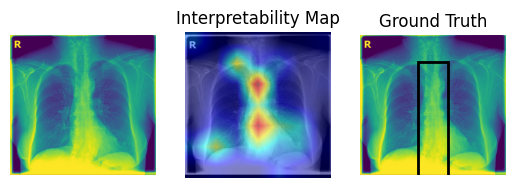

[{'dice_at_0.3': 0.6283971667289734, 'dice_at_0.4': 0.635047197341919, 'dice_at_0.5': 0.5268056988716125}]
106375161187957362257225225066251971601_1kgy4k.png
tensor([0.2649, 0.6624, 0.0090, 0.0637], device='cuda:0')


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
0,0 (0.00),0,0.00,healthy x - ray


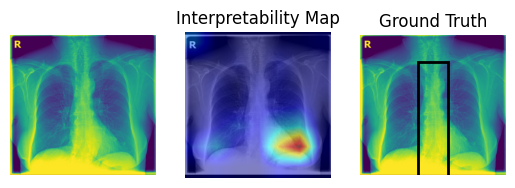

[{'dice_at_0.3': 0.03927987068891525, 'dice_at_0.4': 0.008150885812938213, 'dice_at_0.5': 0.0}]
106375161187957362257225225066251971601_1kgy4k.png


[{'dice_at_0.3': 0.03927987068891525,
  'dice_at_0.4': 0.008150885812938213,
  'dice_at_0.5': 0.0}]

In [33]:
# show_for_one_image("101354916913099012081924155376991837012_81ss65.png",custom_texts=["There is a right pleural effusion."], model=model)
# show_for_one_image("101354916913099012081924155376991837012_81ss65.png",custom_texts=["There is a left pleural effusion."], model=model)
# show_for_one_image("101354916913099012081924155376991837012_81ss65.png",custom_texts=["There is a no evidence of pleural effusion."], model=model)
show_for_one_image("106375161187957362257225225066251971601_1kgy4k.png",custom_texts=["Dextroconvex or levoconvex spinal curvature with associated vertebral rotation, consistent with scoliosis."], model=model)
show_for_one_image("106375161187957362257225225066251971601_1kgy4k.png", model=model)
show_for_one_image("106375161187957362257225225066251971601_1kgy4k.png",custom_texts=["Healthy x-ray"], model=model)


In [41]:
thresholds = [0.3,0.4,0.5]

# Move the model to the GPU if it's not already there
model = model.to(device)

dice_results = []
for n, (image_id, image, texts, bboxes, offsets) in enumerate(padchest_abnormal_loader):
    image = image.unsqueeze(0).to(device)

    num_findings_in_image = len(texts)
    if texts:
      text = clip.tokenize(texts).to(device)

      R_text, R_image = interpret(model=model, image=image, texts=text, device=device)
      batch_size = text.shape[0]
      for i in range(batch_size):
        # show_heatmap_on_text(texts[i], text[i], R_text[i])
        # show_image_relevance(R_image[i], image, orig_image=Image.open(f"{IMAGE_FOLDER}/{image_id}"), bboxes=bboxes[i])
        # plt.show()        
        results = dice_score(R_image[i], bboxes[i], thresholds)
        results['no_findings_in_image'] = num_findings_in_image
        results['bbox_percent'] = sum(bbox_percent(bbox) for bbox in bboxes[i])
        dice_results.append(results)


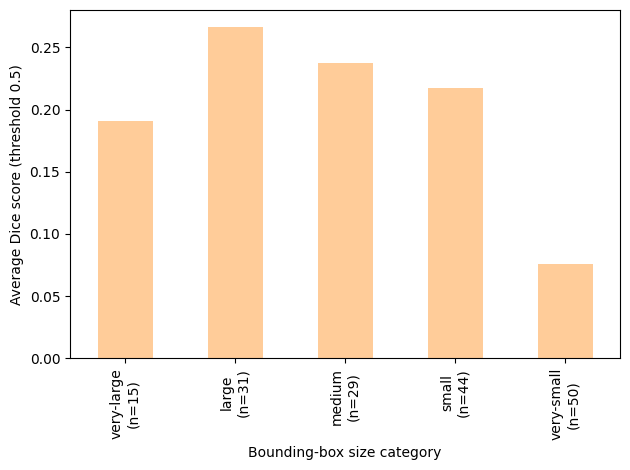

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame(dice_results)

labels = ["very-small", "small", "medium", "large", "very-large"]
reorder = ["very-large", "large", "medium", "small", "very-small"]
df["bbox_category"] = pd.cut(
    df["bbox_percent"],
    bins=[-float("inf"), 0.025, 0.075, 0.125, 0.25, float("inf")],
    labels=labels,
    right=False,
)

grouped = df.groupby("bbox_category", observed=False)["dice_at_0.5"]
mean_dice = grouped.mean().reindex(reorder)
counts = grouped.count().reindex(reorder)

ax = mean_dice.plot(kind="bar",color="#ffcc99")
ax.set_xlabel("Bounding-box size category")
ax.set_ylabel("Average Dice score (threshold 0.5)")
ax.set_xticks(
    range(len(reorder)),
    [f"{category}\n(n={count})" for category, count in zip(reorder, counts)],
)
plt.tight_layout()
plt.show()

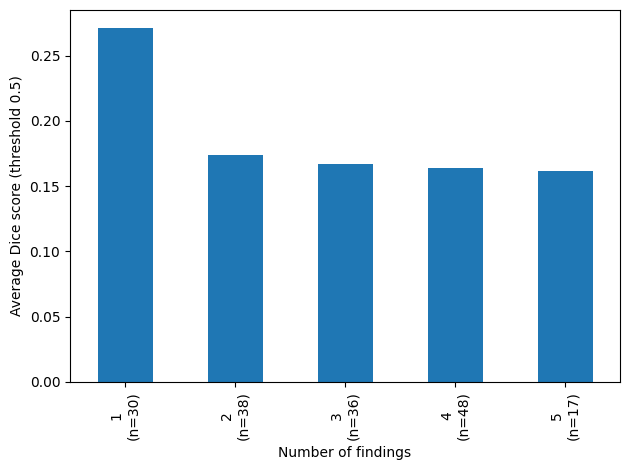

In [60]:
df['no_findings_in_image_cap'] = np.where(df['no_findings_in_image'] > 5, 5,df['no_findings_in_image'])

grouped = df.groupby("no_findings_in_image_cap", observed=False)["dice_at_0.5"]
mean_dice = grouped.mean()
counts = grouped.count()
categories = mean_dice.index

ax = mean_dice.plot(kind="bar")
ax.set_xlabel("Number of findings")
ax.set_ylabel("Average Dice score (threshold 0.5)")
ax.set_xticks(
    range(len(categories)),
    [f"{category}\n(n={count})" for category, count in zip(categories, counts)],
)
plt.tight_layout()
plt.show()

In [40]:
with open(f"/content/drive/MyDrive/Research/data/padchest-gr/dice_results.json","w") as f:
  json.dump(df.to_json(), f)


### Finding x-rays with high disease counts


In [ ]:
from typing import List, Union
from pathlib import Path
import h5py
from tqdm import tqdm

def img_to_hdf5(cxr_paths: List[Union[str, Path]], out_filepath: str, resolution=320, metadata: dict = None): 
    """
    Convert directory of images into a .h5 file given paths to all 
    images. 
    """
    dset_size = len(cxr_paths)
    failed_images = []
    with h5py.File(out_filepath,'w') as h5f:
        samples = h5f.create_group("samples")
        utf8 = h5py.string_dtype(encoding="utf-8")

        for idx, path in enumerate(tqdm(cxr_paths)):
            image_id = path.split("/")[-1] 
            sample = samples.create_group(image_id)
            try: 
                # read image using cv2
                img = cv2.imread(str(path))
                # convert to PIL Image object
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img_pil = Image.fromarray(img)
                # preprocess
                img = preprocess(img_pil, desired_size=resolution)     
                sample.create_dataset("image", data=img)
            except Exception as e: 
                failed_images.append((path, e))
    print(f"{len(failed_images)} / {len(cxr_paths)} images failed to be added to h5.", failed_images)

In [67]:
import glob
files = glob.glob("/content/drive/MyDrive/Research/data/padchest-gr/PadChest_GR/*.png")

img_to_hdf5(files, out_filepath="/content/drive/MyDrive/Research/data/padchest-gr/PadChest_GR.h5", resolution=224, metadata=gt_by_image)

  0%|          | 0/128 [00:00<?, ?it/s]

100%|██████████| 128/128 [00:35<00:00,  3.63it/s]


128 / 128 images failed to be added to h5. [('/content/drive/MyDrive/Research/data/padchest-gr/PadChest_GR/102443594909091188793406228640741714201_x3t2lt.png', AttributeError("module 'PIL.Image' has no attribute 'ANTIALIAS'")), ('/content/drive/MyDrive/Research/data/padchest-gr/PadChest_GR/102833253821298909312539570021866142803_qfbvu7.png', AttributeError("module 'PIL.Image' has no attribute 'ANTIALIAS'")), ('/content/drive/MyDrive/Research/data/padchest-gr/PadChest_GR/106375161187957362257225225066251971601_1kgy4k.png', AttributeError("module 'PIL.Image' has no attribute 'ANTIALIAS'")), ('/content/drive/MyDrive/Research/data/padchest-gr/PadChest_GR/101556934868825149603490715609818327608_5tfnpm.png', AttributeError("module 'PIL.Image' has no attribute 'ANTIALIAS'")), ('/content/drive/MyDrive/Research/data/padchest-gr/PadChest_GR/105149241084163531654097774373464453478_fr4vl4.png', AttributeError("module 'PIL.Image' has no attribute 'ANTIALIAS'")), ('/content/drive/MyDrive/Research/da

In [ ]:
from torch.utils.data import Dataset

class CXRDataset(Dataset):
    def __init__(self, image_path, annotations, transform=None):
        self.h5_path = image_path
        self.transform = transform

        # Build this from your JSON records, each of which has an image_id.
        self.annotations = {
            record["image_id"]: record
            for record in annotations
        }

    def __getitem__(self, idx):
        image = self.images[idx]  # HDF5 image at this index
        image_id = self.image_ids[idx]  # ID stored alongside the HDF5 images
        metadata = self.annotations[image_id]

        if self.transform:
            image = self.transform(image)

        return image, metadata

In [63]:
dataset = CXRDataset(h5_path = "/content/drive/MyDrive/Research/data/padchest-gr/PadChest_GR.h5", transform = None)

TypeError: CXRDataset.__init__() missing 1 required positional argument: 'annotations'

In [42]:
padchest_transforms

Compose(
    <function to_float_tensor at 0x7f2bfb77fe20>
    <function <lambda> at 0x7f2bfb77fce0>
    Normalize(mean=(101.48761, 101.48761, 101.48761), std=(83.43944, 83.43944, 83.43944))
)

In [43]:
test_image = dataset[0]['img']

In [46]:
img = test_image

In [47]:
# CheXzero transforms
img = img.unsqueeze(0).to(device)

texts, bboxes = get_texts_and_bboxes(image_id, gt_by_image)

# texts = ["Cardiomegaly", "Bilateral costophrenic angle blunting suggesting pleural effusions.", "Prominent hila, likely vascular.", "New right upper lobe alveolar infiltrate, possibly cardiogenic or inflammatory/infectious."]
# texts = ["Persistent areas of increased lucency with reduced attenuation of vascular markings, suggestive of air trapping.",     "Increased radiolucency with reduced vascular markings, consistent with air trapping.",
#     "Hyperlucent appearance with diminished vascular markings, suggestive of air trapping.",
#     "Increased lung lucency with evidence of retained air.",
#     "Persistent hyperlucency with features suggestive of air trapping.",
#     "Increased radiolucency with reduced vascular conspicuity, compatible with air trapping.",  "Air trapping", "No findings","Healthy chest x-ray"]
text = clip.tokenize(texts).to(device)

thresholds = [0.3,0.4,0.5]

# Move the model to the GPU if it's not already there
model = model.to(device)

R_text, R_image = interpret(model=model, image=img, texts=text, device=device)
batch_size = text.shape[0]
dice_results = []
gt_index = 0
for i in range(batch_size):
  show_heatmap_on_text(texts[i], text[i], R_text[i])
  show_image_relevance(R_image[i], img, orig_image=Image.open(img_path), bboxes=bboxes[gt_index])
  plt.show()
  dice_results.append(dice_score(R_image[i], bboxes[gt_index], thresholds))

print(dice_results)

NameError: name 'image_id' is not defined

In [38]:
test_image.shape

torch.Size([3, 224, 224])

In [44]:
out = padchest_transforms(dataset[0]['img'])

In [41]:
len(files)

129

In [43]:
files[0].split("/")[-1]

'102443594909091188793406228640741714201_x3t2lt.png'

In [68]:
img_gt = gt_by_image[img_id]
findings = img_gt['findings']


In [ ]:
x1, y1, x2, y2 = bbox
width, length = x2 - x1, y2 - y1
bboxes_percent_img = length * width

In [112]:
# Image from padchest
image_id = "101991612320249193176205024735415183351_2_95q7wr.png"
def get_dice_scores(image_id, model):
  img_path = f"/content/drive/MyDrive/Research/data/padchest-gr/PadChest_GR/{image_id}"
  img = padchest_transforms(Image.open(img_path))
  # CheXzero transforms
  img = img.unsqueeze(0).to(device)

  texts, bboxes = get_texts_and_bboxes_abnormal(image_id, gt_by_image)

  # texts = ["Cardiomegaly", "Bilateral costophrenic angle blunting suggesting pleural effusions.", "Prominent hila, likely vascular.", "New right upper lobe alveolar infiltrate, possibly cardiogenic or inflammatory/infectious."]
  text = clip.tokenize(texts).to(device)

  thresholds = [0.3,0.4,0.5]

  # Move the model to the GPU if it's not already there
  model = model.to(device)

  R_text, R_image = interpret(model=model, image=img, texts=text, device=device)
  batch_size = text.shape[0]
  dice_results = []
  for i in range(batch_size):
    # show_heatmap_on_text(texts[i], text[i], R_text[i])
    # show_image_relevance(R_image[i], img, orig_image=Image.open(img_path), bboxes=bboxes[i])
    # plt.show()
    dice_results.append(dice_score(R_image[i], bboxes[i], thresholds))

  dice_per_thresh = {}
  for i, thresh in enumerate(thresholds):
    # Get macro-average dice, mean dice per disease for a given image
    dice_per_thresh[thresh] = np.mean([d['dice'][i] for d in dice_results])

  return dice_per_thresh

In [113]:
get_dice_scores(image_id, model)

{0.3: np.float64(0.27853325195610523),
 0.4: np.float64(0.2461454626172781),
 0.5: np.float64(0.20004995446652174)}

In [128]:
# Create a function that calculates the number of (i) findings (ii) percentage of disease with respect to background (iii) number of disinct boxes for disease

data_findings = []

for num_imgs, img_path in enumerate(files):
  img_id = img_path.split("/")[-1]
  img_gt = gt_by_image[img_id]

  findings = img_gt['findings']

  if any(i['abnormal'] for i in findings):
    dice_scores = get_dice_scores(img_id, model)

    data_findings.append(
        {"findings_no":len([i for i in findings if i['abnormal'] and i['boxes']]),
        "bbox_percentage_of_image": sum(sum(bbox_percent(bb) for bb in b['boxes']) for b in findings if b['abnormal'] and b['boxes']),
        "bboxes_no": sum(len(b['boxes']) for b in findings if b['abnormal'] and b['boxes'])} | dice_scores
    )

  # if num_imgs > 10:
  #   break


In [130]:
with open(f"/content/drive/MyDrive/Research/data/padchest-gr/images_scored.json","w") as f:
  json.dump(data_findings, f)


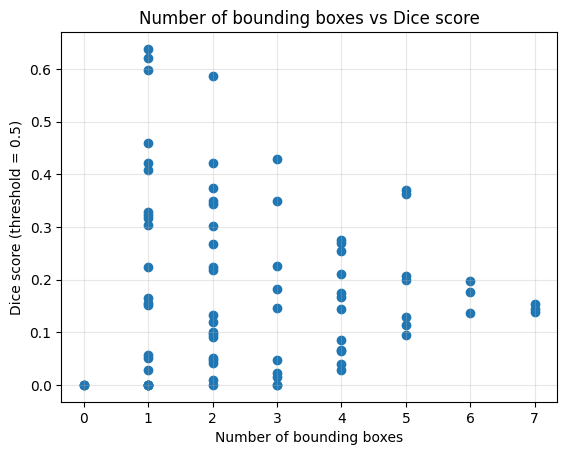

In [131]:
import matplotlib.pyplot as plt

x = [d['bboxes_no'] for d in data_findings]
y = [d[0.5] for d in data_findings]

plt.scatter(x, y)
plt.xlabel('Number of bounding boxes')
plt.ylabel('Dice score (threshold = 0.5)')
plt.title('Number of bounding boxes vs Dice score')
plt.xticks(sorted(set(x)))
plt.grid(alpha=0.3)
plt.show()

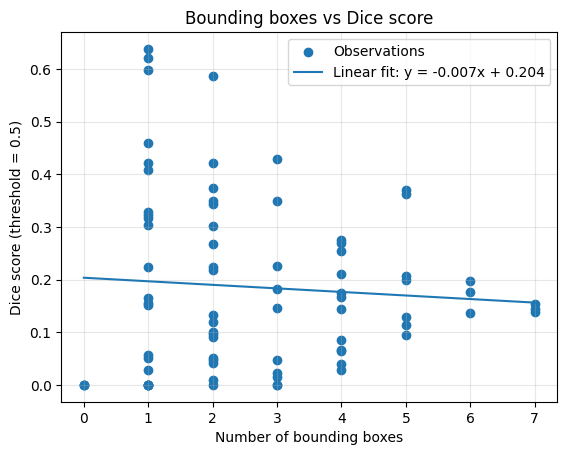

In [135]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([d['bboxes_no'] for d in data_findings])
y = np.array([d[0.5] for d in data_findings])

# Fit a straight line: y = mx + c
m, c = np.polyfit(x, y, 1)

plt.scatter(x, y, label='Observations')
plt.plot(
    np.linspace(x.min(), x.max(), 100),
    m * np.linspace(x.min(), x.max(), 100) + c,
    label=f'Linear fit: y = {m:.3f}x + {c:.3f}'
)

plt.xlabel('Number of bounding boxes')
plt.ylabel('Dice score (threshold = 0.5)')
plt.title('Bounding boxes vs Dice score')
plt.xticks(sorted(set(x)))
plt.legend()
plt.grid(alpha=0.3)
plt.show()